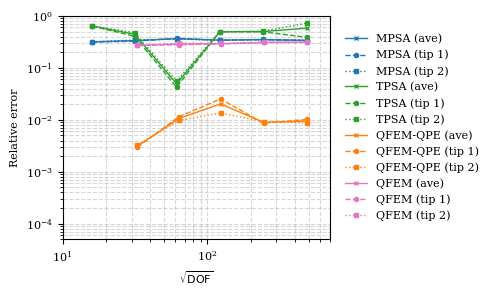

In [1]:
# Only for plot SIF results for all grid sizes, compared with FEM in Banks-Sills and Sherman (1986)
from __future__ import annotations
from dataclasses import dataclass

import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# MPSA
mpsa_dofs = np.array([
    16.0, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa = np.array([
    0.31619868, 0.33475893, 0.36373258, 0.34144228, 0.34923245, 0.33763584
]) 

err_tip1_mpsa = np.array([
    0.31370035, 0.32585493, 0.37037359, 0.33875787, 0.35236015, 0.33380345
])

err_tip2_mpsa = np.array([
    0.31867742, 0.34343217, 0.35696804, 0.34410575, 0.34607648, 0.34142522
]) 

# TPSA
tpsa_dofs = np.array([
    16.0, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_tpsa = np.array([
    0.63857338, 0.4429862, 0.04949826, 0.49604536, 0.50083407, 0.58109526
]) 

err_tip1_tpsa = np.array([
    0.63716795, 0.40409754, 0.04254083, 0.49646313, 0.49288288, 0.38613973
])

err_tip2_tpsa = np.array([
    0.63997572, 0.47872616, 0.05559166, 0.49562723, 0.50866099, 0.72542368
]) 

# QFEM-QPE
femqpe_dofs = np.array([
    32.86335345, 63.7495098, 123.48279232, 244.94897428, 488.99079746
])

err_ave_femqpe = np.array([
    0.00311614, 0.01066066, 0.02022317, 0.0089286, 0.009458
]) 

err_tip1_femqpe = np.array([
    0.00298013, 0.01151875, 0.02520013, 0.00859656, 0.01019192
])

err_tip2_femqpe = np.array([
    0.00324645, 0.00972717, 0.01352428, 0.00924872, 0.00866211
]) 

# QFEM
fem_dofs = np.array([
    32.86335345, 63.7495098, 123.48279232, 244.94897428, 488.99079746
])

err_ave_fem = np.array([
    0.27031229, 0.28781617, 0.29194237, 0.30881851, 0.3104813
]) 

err_tip1_fem = np.array([
    0.27018658, 0.27816853, 0.28828184, 0.30803392, 0.30831018
])

err_tip2_fem = np.array([
    0.27043794, 0.29715075, 0.29555758, 0.30960111, 0.31263735
]) 

# Reference line


# Plot SIF KI
mpl.rcParams.update({
    "font.family": "serif",     
    "font.size": 8,             
    "axes.labelsize": 8,       
    "axes.titlesize": 8,        
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "lines.linewidth": 1.0,      
    "lines.markersize": 3.0,       
    "mathtext.fontset": "dejavusans",  
})
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))   # Scientific form

fig, ax = plt.subplots(figsize=(5.0, 3.0))   # inches
# MPSA
ax.loglog(
    mpsa_dofs,
    err_ave_mpsa,
    'x-',
    color='tab:blue',
    label="MPSA (ave)"
)
ax.loglog(
    mpsa_dofs,
    err_tip1_mpsa,
    'o--',
    color='tab:blue',
    label="MPSA (tip 1)"
)
ax.loglog(
    mpsa_dofs,
    err_tip2_mpsa,
    's:',
    color='tab:blue',
    label="MPSA (tip 2)"
)
# TPSA
ax.loglog(
    tpsa_dofs,
    err_ave_tpsa,
    'x-',
    color='tab:green',
    label="TPSA (ave)"
)
ax.loglog(
    tpsa_dofs,
    err_tip1_tpsa,
    'o--',
    color='tab:green',
    label="TPSA (tip 1)"
)
ax.loglog(
    tpsa_dofs,
    err_tip2_tpsa,
    's:',
    color='tab:green',
    label="TPSA (tip 2)"
)
# QFEM-QPE
ax.loglog(
    femqpe_dofs,
    err_ave_femqpe,
    'x-',
    color='tab:orange',
    label="QFEM-QPE (ave)"
)
ax.loglog(
    femqpe_dofs,
    err_tip1_femqpe,
    'o--',
    color='tab:orange',
    label="QFEM-QPE (tip 1)"
)
ax.loglog(
    femqpe_dofs,
    err_tip2_femqpe,
    's:',
    color='tab:orange',
    label="QFEM-QPE (tip 2)"
)
# QFEM
ax.loglog(
    fem_dofs,
    err_ave_fem,
    'x-',
    color='tab:pink',
    label="QFEM (ave)"
)
ax.loglog(
    fem_dofs,
    err_tip1_fem,
    'o--',
    color='tab:pink',
    label="QFEM (tip 1)"
)
ax.loglog(
    fem_dofs,
    err_tip2_fem,
    's:',
    color='tab:pink',
    label="QFEM (tip 2)"
)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(10, 700)
ax.set_ylim(0.00005, 1.0)
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.set_xlabel(r"$\sqrt{\mathrm{DOF}}$")
ax.set_ylabel("Relative error")

# ax.legend(loc="lower left")
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  
    frameon=False
)
ax.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
# plt.savefig("KII_convergence_ws.tiff", format="tiff", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
# plt.savefig("sneddon_singularity.eps", format="eps", dpi=300, bbox_inches="tight")
plt.show()